[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/recsys/08-beyond-accuracy.ipynb)

# Beyond Accuracy: Coverage, Popularity Bias and Who Gets Served

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Compute coverage, concentration (Gini), mean popularity, novelty and genre diversity of a set of recommendation lists.</li>
<li>Show how much more a model recommends the popular head of the catalogue than the real hits are there.</li>
<li>Build a popularity-penalising re-ranker and read the accuracy-versus-coverage trade-off from a table.</li>
<li>Break accuracy down by user group to see who the model actually serves.</li>
</ul>
</div>

**Prerequisites:** [Matrix factorisation](05-factorisation.ipynb). **Dataset:** MovieLens small. **Time:** about 35 minutes.

## The situation

Suppose the best model so far wins on NDCG. A product owner asks three more questions. *Do we recommend the whole catalogue, or the same few hits?* *Are the lists a little more than "the popular movies, filtered"?* *Who is this better for: heavy users or everyone?* None of them is answered by the accuracy number, and each can change a decision.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_movielens, recsys as rs, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.3f}".format)

## Maths ↔ code

Let $L_u$ be user $u$'s list of $k$ movies, $n_i$ the number of training ratings of movie $i$, $U$ the number of users and $I$ the number of movies.

- **Coverage:** the share of movies that appear in at least one list, $\left|\bigcup_u L_u\right| / I$ (`rs.coverage`). With $U$ users and lists of $k$ it cannot exceed $\min(1, Uk/I)$.
- **Gini:** how unequally the recommendation slots are spread over movies: 0 if every movie is recommended equally often, near 1 if a few movies take nearly all slots (`rs.gini`).
- **Mean popularity:** the average $n_i$ over recommended movies (`rs.mean_popularity`).
- **Novelty:** the average self-information $-\log_2(n_i/U)$ of recommended movies, in bits; higher is more obscure (`rs.novelty`).
- **Diversity:** the average pairwise cosine *distance* between the genre vectors of the movies inside a list (`rs.intra_list_diversity`).

## 0. Setup: the models of the last pages, and a few more

In [2]:
ratings = load_movielens().ratings
movies = load_movielens().movies
task = rs.make_task(ratings)
n_users, n_items = task.X.shape
k = 10

liked = task.X.copy(); liked.data = (liked.data >= 4).astype(np.float32); liked.eliminate_zeros()
item_counts = np.asarray(task.B.sum(axis=0)).ravel()                  # how many training ratings each movie has
genres, genre_names = rs.genre_matrix(movies, task.index)

models = {                                                            # settings chosen on validation on the earlier pages
    "popularity": rs.broadcast(rs.popularity(task.B), n_users),
    "item-item (likes)": rs.item_knn_scores(liked, rs.item_similarity(liked, k=50, shrink=10)),
    "implicit ALS (likes)": rs.als_implicit(liked, factors=32, reg=10, alpha=1, iters=10, seed=0).scores(),
    "explicit MF (predicted rating)": rs.als_explicit(task.X, factors=20, reg=0.2, iters=15).scores(),
    "random": np.random.default_rng(0).random(task.B.shape),
}
lists = {name: rs.top_k(S, task.B, k) for name, S in models.items()}

def profile(top):
    return {"NDCG@10": rs.rank_metrics(top, task.relevant)["ndcg"].mean(),
            "coverage": rs.coverage(top, n_items), "Gini": rs.gini(top, n_items),
            "mean popularity": rs.mean_popularity(top, item_counts), "novelty (bits)": rs.novelty(top, item_counts, n_users),
            "genre diversity": rs.intra_list_diversity(top, genres)}

print(f"{n_users} users x {k} slots = {n_users * k:,} slots for {n_items:,} movies, so coverage cannot exceed {n_users * k / n_items:.0%}")
table = pd.DataFrame({name: profile(top) for name, top in lists.items()}).T
assert table["coverage"].idxmax() == "random" and table.loc["random", "NDCG@10"] < 0.01          # guards the reading below
assert table.loc["explicit MF (predicted rating)", "mean popularity"] < 5 and table.loc["implicit ALS (likes)", "coverage"] < 0.06
table

610 users x 10 slots = 6,100 slots for 9,724 movies, so coverage cannot exceed 63%


,NDCG@10,coverage,Gini,mean popularity,novelty (bits),genre diversity
popularity,0.074,0.010,0.998,216.787,1.520,0.704
item-item (likes),0.115,0.050,0.987,144.896,2.271,0.690
implicit ALS (likes),0.121,0.048,0.985,139.134,2.324,0.689
explicit MF (predicted rating),0.000,0.011,0.998,1.078,9.188,0.647
random,0.002,0.470,0.621,7.652,7.718,0.759


The ceiling first: 610 users with ten slots each give 6,100 slots for 9,724 movies, so no model can cover more than 63% of the catalogue. Against that ceiling:

- **Popularity** gives everybody nearly the same list: 98 distinct movies (1.0% coverage) and a Gini of 0.998, meaning almost all the slots go to a handful of movies.
- **Item-item and ALS** are more accurate (0.115 and 0.121) and reach about 5% of the catalogue, with a Gini still at 0.985 to 0.987. Their lists are only a little less popular than the popularity list (mean 145 and 139 ratings per recommended movie, against 217).
- The **explicit model** has the most obscure lists (a mean of 1.1 ratings per recommended movie, 9.2 bits of novelty) and an NDCG of 0.000: novelty is not quality.
- The **random list** has the highest coverage (47%), the best diversity (0.76) and an accuracy of 0.002: a high number on a beyond-accuracy metric means nothing without accuracy beside it.
- All personalised lists are about as varied inside as the popularity list (genre diversity 0.69 to 0.70 against 0.70).

## 1. Popularity bias: where the recommendations sit, against where the hits sit

Call the most-rated tenth of the movies the **head**. Compare the share of *recommendations* that fall in the head with the share of the real, held-out *hits* that do:

In [3]:
head = item_counts >= np.sort(item_counts)[::-1][int(0.1 * n_items) - 1]
hit_share = task.relevant[:, np.flatnonzero(head)].sum() / task.relevant.nnz
exposure = pd.DataFrame({"share of slots in the head": {name: head[top].mean() for name, top in lists.items()}})
print(f"share of the test hits that are in the head: {hit_share:.1%}")
assert hit_share < 0.6 and all(exposure.loc[m, "share of slots in the head"] > 0.95 for m in ("popularity", "item-item (likes)", "implicit ALS (likes)"))
exposure

share of the test hits that are in the head: 54.5%


,share of slots in the head
popularity,1.000
item-item (likes),0.984
implicit ALS (likes),0.995
explicit MF (predicted rating),0.000
random,0.099


Only **54.5% of the held-out hits are in the head**, yet **98% to 100% of the slots of all three real recommenders are**: popularity 100%, item-item 98.4%, ALS 99.5%. The models are far more head-heavy than the data: nearly half of what users go on to like lies outside the head, and almost none of it is recommended. Only the explicit model (0%) and the random list (10%) leave the head, and both at no accuracy. The accuracy metric rewards this: most hits are in the head, so recommending only the head scores well.

## 2. Re-ranking against popularity

A simple, widely used remedy: take a model's scores, standardise them per user, and **subtract a multiple $\beta$ of the standardised log-popularity** of each movie. $\beta = 0$ is the original list; larger $\beta$ pushes lists toward the tail. Sweep $\beta$ and watch accuracy, coverage and novelty together.

,NDCG@10,change,coverage,mean popularity,novelty (bits)
beta,,,,,
0.000,0.121,,0.048,139.134,2.324
0.250,0.120,"-0.0011 [-0.0028, +0.0005]",0.052,135.909,2.395
0.500,0.118,"-0.0024 [-0.0047, -0.0001]",0.056,133.067,2.457
1.000,0.113,"-0.0074 [-0.0120, -0.0028]",0.065,126.179,2.640
1.500,0.105,"-0.0154 [-0.0217, -0.0092]",0.072,117.387,2.986
2.000,0.086,"-0.0352 [-0.0437, -0.0267]",0.065,96.882,4.167
3.000,0.025,"-0.0956 [-0.1074, -0.0838]",0.022,23.811,8.252


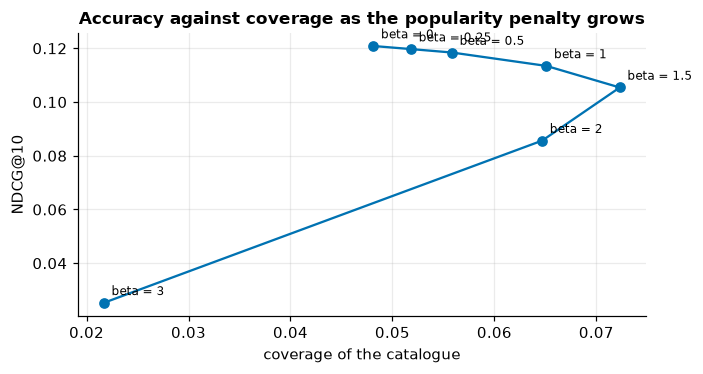

In [4]:
def standardise(S):
    return (S - S.mean(axis=1, keepdims=True)) / np.maximum(S.std(axis=1, keepdims=True), 1e-9)

log_pop = np.log1p(item_counts)
log_pop = (log_pop - log_pop.mean()) / log_pop.std()
als = models["implicit ALS (likes)"]

betas = (0, 0.25, 0.5, 1, 1.5, 2, 3)
reranked = {beta: rs.top_k(standardise(als) - beta * log_pop[None, :], task.B, k) for beta in betas}
base = rs.rank_metrics(reranked[0], task.relevant)["ndcg"]

rows = {}
for beta, top in reranked.items():
    m = rs.rank_metrics(top, task.relevant)["ndcg"]
    d = rs.paired_difference(m, base)
    rows[beta] = {"NDCG@10": m.mean(), "change": "" if beta == 0 else f"{d['diff']:+.4f} [{d['lo']:+.4f}, {d['hi']:+.4f}]",
                  "coverage": rs.coverage(top, n_items), "mean popularity": rs.mean_popularity(top, item_counts),
                  "novelty (bits)": rs.novelty(top, item_counts, n_users)}
sweep = pd.DataFrame(rows).T.rename_axis("beta")
d05 = rs.paired_difference(rs.rank_metrics(reranked[0.5], task.relevant)["ndcg"], base)
assert sweep.loc[0.5, "coverage"] > sweep.loc[0, "coverage"] and d05["hi"] < 0 and sweep["coverage"].max() < 0.1       # guards the reading below
display(sweep)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(sweep["coverage"], sweep["NDCG@10"], marker="o", color=style.BLUE)
for beta, row in sweep.iterrows():
    ax.annotate(f"beta = {beta:g}", (row["coverage"], row["NDCG@10"]), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set(xlabel="coverage of the catalogue", ylabel="NDCG@10", title="Accuracy against coverage as the popularity penalty grows")
plt.tight_layout(); plt.show()

Read the table as a menu.

- **$\beta = 0.5$** costs 0.0024 NDCG (2%, interval [-0.0047, -0.0001], so a real but small loss) and lifts coverage from 4.8% to 5.6% and novelty by about 0.13 bits.
- **$\beta = 1$** costs 0.0074 (6%) and gives 6.5% coverage.
- **$\beta = 1.5$** costs 0.0154 (13%) for 7.2% coverage, the most any setting reaches.
- Beyond that it falls apart: at $\beta = 2$ accuracy is down 29% and coverage is *lower* again (6.5%), and at 3 both collapse.

Two lessons. A **small penalty is nearly free**; a large one destroys accuracy and buys nothing. And **coverage never passes about 7%**, though 63% is feasible: most movies have too few ratings for any model to know who would like them, so a re-ranker has little reliable to put in their place. Choosing between $\beta = 0.5$ and 1 is a business judgement about how much accuracy a third more coverage is worth; the table gives the price, with intervals.

## 3. Who is served?

An average hides who the model works for. Split users into thirds by how many ratings they have in the training data, and compare popularity with the ALS model in each third:

In [5]:
activity = np.asarray(task.B.sum(axis=1)).ravel()
group = pd.Series(pd.qcut(activity, 3, labels=["light", "medium", "heavy"]), name="user group")
by_group = {}
per_user = {name: rs.rank_metrics(lists[name], task.relevant)["ndcg"] for name in ("popularity", "implicit ALS (likes)")}
for g in ("light", "medium", "heavy"):
    members = per_user["popularity"].index[group.iloc[per_user["popularity"].index].to_numpy() == g]
    gain = rs.paired_difference(per_user["implicit ALS (likes)"][members], per_user["popularity"][members])
    by_group[g] = {"users": len(members), "median training ratings": int(np.median(activity[members])),
                   "popularity": per_user["popularity"][members].mean(), "implicit ALS": per_user["implicit ALS (likes)"][members].mean(),
                   "ALS gain": f"{gain['diff']:+.4f} [{gain['lo']:+.4f}, {gain['hi']:+.4f}]"}
groups_table = pd.DataFrame(by_group).T
assert all(rs.paired_difference(per_user["implicit ALS (likes)"][per_user["popularity"].index[group.iloc[per_user["popularity"].index].to_numpy() == g]],
                                per_user["popularity"][per_user["popularity"].index[group.iloc[per_user["popularity"].index].to_numpy() == g]])["lo"] > 0
           for g in ("light", "medium", "heavy"))
groups_table

,users,median training ratings,popularity,implicit ALS,ALS gain
light,197,23,0.057,0.106,"+0.0487 [+0.0260, +0.0714]"
medium,198,59,0.061,0.098,"+0.0362 [+0.0174, +0.0549]"
heavy,197,214,0.105,0.159,"+0.0548 [+0.0336, +0.0761]"


The ALS model beats popularity in **all three** user groups, each interval above zero: for light users (median 23 training ratings) 0.057 to 0.106, for medium users (59) 0.061 to 0.098, for heavy users (214) 0.105 to 0.159. Heavy users get the highest scores and the largest absolute gain (+0.055), but the three intervals overlap, so the data does not show that the gain differs between groups. In relative terms the lighter users gain *more* (about 1.9 times popularity's score, against 1.5 times for the heavy users). The overall 0.121 is an average over very different experiences: the medium group scores 0.098, a fifth below the average.

<div class="admonition warning">
<p class="admonition-title">Watch out</p>
<p>Every metric on this page can be gamed on its own. A random list has the highest coverage and zero accuracy; the explicit model has the highest novelty and zero accuracy. Always read accuracy and a beyond-accuracy metric <em>together</em>, as a trade-off, never one alone.</p>
</div>

## Decision guide

| Question | Measure | Act when |
|---|---|---|
| Do we show the whole catalogue? | Coverage, Gini | Almost every list is the same few titles and the business needs the tail seen |
| Are we just recommending the head? | Share of slots in the head against the share of hits there | The model concentrates much more than the data does |
| Are lists samey inside? | Intra-list diversity | Users see ten near-identical items |
| Is anyone left behind? | Accuracy by user group, with a paired interval | One group gets much less benefit than another |
| How much accuracy will we give up? | The accuracy-against-coverage table | Pick the knee: a large coverage gain for a small, interval-checked loss |

## Check yourself

<details class="question">
<summary>1. A random recommender has the best coverage of all the models. Why is coverage alone a poor target?</summary>

Coverage counts which items appear, not whether the user wants them. A random list touches the whole catalogue and helps nobody. Coverage is only informative next to accuracy: the question is how much of the catalogue you can reach *without* giving up the hits.

</details>

<details class="question">
<summary>2. Why can a popularity penalty raise coverage only a little here, however large you make it?</summary>

The ratings are concentrated: most movies have very little data, so a model has little reason to prefer one of them over another and a large penalty replaces informed picks with arbitrary ones. Beyond a point, accuracy collapses before coverage grows much, which is what the table shows.

</details>

## Exercises

<details class="question">
<summary>Exercise 1 (easy): what share of the movies that the ALS model recommends at least once are in the head?</summary>

```python
recommended = np.unique(lists["implicit ALS (likes)"])
print(head[recommended].mean())
```

The ALS lists contain 468 distinct movies, and **95.7% of them (448) are in the head**, against 10% of the whole catalogue. The part of the catalogue a model can reach is almost entirely the part everyone already sees.

</details>

<details class="question">
<summary>Exercise 2 (medium): the penalty above uses the log of popularity. Use a plain rank-based penalty (subtract <code>beta</code> times the standardised popularity rank) and compare the NDCG-versus-coverage curve.</summary>

```python
rank = pd.Series(item_counts).rank(pct=True).to_numpy()
rank = (rank - rank.mean()) / rank.std()
top = rs.top_k(standardise(als) - 1.0 * rank[None, :], task.B, k)
print(rs.rank_metrics(top, task.relevant)["ndcg"].mean(), rs.coverage(top, n_items))
```

At equal $\beta$ the rank penalty is gentler on accuracy (0.1171 at $\beta = 1$, against 0.1134 for the log penalty) but it cannot raise coverage: it stays between 4.9% and 5.1% for $\beta$ from 0.5 to 1.5, while the log penalty reaches 7.2%. Compare penalties at equal *coverage*, not equal $\beta$: here the log penalty is the only one that reaches into the tail.

</details>

<details class="question">
<summary>Exercise 3 (hard): implement a greedy diversity re-ranker (MMR): from the top 30 candidates, repeatedly pick the movie maximising <code>(1 - lam) * score - lam * (largest genre similarity to the movies already picked)</code>. Does it raise genre diversity? What does it cost in NDCG?</summary>

Work out first what the maximum possible diversity gain is, using the table: the random list has a diversity of about 0.76 and the ALS list about 0.69. A re-ranker cannot be expected to gain much more than that gap.

</details>

## Recap

- **Accuracy is not the whole story:** coverage, Gini, mean popularity, novelty and diversity describe the lists the user actually sees.
- Models **recommend the head much more than the hits live there**; the collaborative models are barely less concentrated than plain popularity.
- A **popularity penalty** buys coverage at a price in accuracy; read the table for the knee, and check each loss with a paired interval.
- **Averages hide who is served**: split by user group.
- Each metric can be gamed alone. Report them as a trade-off.